# E-commerce Sales Analysis

## Project Objective

The objective of this project is to analyze e-commerce sales data using Python and Pandas to understand sales performance, product trends, monthly revenue, country-wise sales, and customer purchasing behavior.

## Tools Used

- Python
- Pandas
- Matplotlib
- Jupyter Notebook

In [1]:
import os
print(os.getcwd())

C:\Users\attit\Python(Data Analysis)


In [2]:
import os
os.chdir(r"D:\ecommerce_project")
print(os.getcwd())

D:\ecommerce_project


In [3]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv("ecommerce_sales.csv")

df.head()

,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,revenue,invoice_month
0,536373,21730,GLASS STAR FROSTED T LIGHT HOLDER,6,01-12-2010 9.02,4.25,17850,United Kingdom,25.50,2010-12
1,536375,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 9.32,3.39,17850,United Kingdom,20.34,2010-12
2,536378,21212,PACK OF 72 RETROSPOT CAKE CASES,120,01-12-2010 9.37,0.42,14688,United Kingdom,50.40,2010-12
3,536385,22168,ORGANISER WOOD ANTIQUE WHITE,2,01-12-2010 9.56,8.50,17420,United Kingdom,17.00,2010-12
4,536390,21080,SET/20 RED RETROSPOT PAPER NAPKINS,96,01-12-2010 10.19,0.64,17511,United Kingdom,61.44,2010-12


## 1. Data Exploration

In this section, we will examine the dataset's size, column names, data types, and missing values to understand the data before analysis.

In [4]:
df.shape

(10000, 10)

In [5]:
df.columns

Index(['invoice', 'stockcode', 'description', 'quantity', 'invoicedate',
       'price', 'customer_id', 'country', 'revenue', 'invoice_month'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   invoice        10000 non-null  int64  
 1   stockcode      10000 non-null  object 
 2   description    10000 non-null  object 
 3   quantity       10000 non-null  int64  
 4   invoicedate    10000 non-null  object 
 5   price          10000 non-null  float64
 6   customer_id    10000 non-null  int64  
 7   country        10000 non-null  object 
 8   revenue        10000 non-null  float64
 9   invoice_month  10000 non-null  object 
dtypes: float64(2), int64(3), object(5)
memory usage: 781.4+ KB


In [7]:
df.isnull().sum()

invoice          0
stockcode        0
description      0
quantity         0
invoicedate      0
price            0
customer_id      0
country          0
revenue          0
invoice_month    0
dtype: int64

In [8]:
df.describe()

,invoice,quantity,price,customer_id,revenue
count,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,560564.152400,13.09580,3.143948,15276.630100,21.674476
std,12979.383729,63.19329,7.738452,1710.532624,64.799868
min,536373.000000,1.00000,0.040000,12347.000000,0.120000
25%,549366.000000,2.00000,1.250000,13974.750000,4.950000
50%,561912.000000,6.00000,1.950000,15113.000000,11.900000
75%,571738.500000,12.00000,3.750000,16790.000000,19.800000
max,581586.000000,4800.00000,389.680000,18287.000000,2959.440000


In [9]:
df.duplicated().sum()

np.int64(1)

## 2. Data Cleaning

In this section, we will remove duplicate records, convert date columns into the correct data types, and verify the dataset after cleaning.

In [10]:
# Check the original number of rows
print("Before cleaning:", df.shape)

# Remove duplicate rows
df = df.drop_duplicates()

# Check the number of rows after cleaning
print("After cleaning:", df.shape)

Before cleaning: (10000, 10)
After cleaning: (9999, 10)


In [11]:
df["invoicedate"].head(10)

0     01-12-2010 9.02
1     01-12-2010 9.32
2     01-12-2010 9.37
3     01-12-2010 9.56
4    01-12-2010 10.19
5    01-12-2010 10.52
6    01-12-2010 11.21
7    01-12-2010 11.29
8    01-12-2010 11.41
9    01-12-2010 11.45
Name: invoicedate, dtype: object

In [12]:
# Convert invoice date to datetime
df["invoicedate"] = pd.to_datetime(
    df["invoicedate"],
    format="%d-%m-%Y %H.%M"
)

# Convert invoice month to datetime
df["invoice_month"] = pd.to_datetime(
    df["invoice_month"],
    format="%Y-%m"
)

# Check data types
df[["invoicedate", "invoice_month"]].dtypes

invoicedate      datetime64[ns]
invoice_month    datetime64[ns]
dtype: object

In [13]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check data types
df.info()

Dataset shape: (9999, 10)

Missing values:
invoice          0
stockcode        0
description      0
quantity         0
invoicedate      0
price            0
customer_id      0
country          0
revenue          0
invoice_month    0
dtype: int64

Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
Index: 9999 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   invoice        9999 non-null   int64         
 1   stockcode      9999 non-null   object        
 2   description    9999 non-null   object        
 3   quantity       9999 non-null   int64         
 4   invoicedate    9999 non-null   datetime64[ns]
 5   price          9999 non-null   float64       
 6   customer_id    9999 non-null   int64         
 7   country        9999 non-null   object        
 8   revenue        9999 non-null   float64       
 9   invoice_month  9999 non-null   datetime64[ns]
dtypes: datetime64[ns

In [14]:
data_quality = pd.DataFrame({
    "Check": [
        "Total Rows",
        "Total Columns",
        "Missing Values",
        "Duplicate Rows"
    ],
    "Result": [
        len(df),
        len(df.columns),
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]
})

data_quality.style.hide(axis="index")

Check,Result
Total Rows,9999
Total Columns,10
Missing Values,0
Duplicate Rows,0


## 3. Revenue Validation

In this section, we verify the accuracy of the revenue values by comparing them with the calculated revenue using quantity multiplied by price.

In [15]:
# Calculate revenue independently
df["calculated_revenue"] = df["quantity"] * df["price"]

# Compare calculated revenue with existing revenue
mismatches = (
    (df["revenue"] - df["calculated_revenue"])
    .abs()
    > 0.01
)

print("Mismatched rows:", mismatches.sum())

Mismatched rows: 0


## 4. Key Performance Indicators (KPIs)

In this section, we calculate important business metrics to understand overall sales performance, including total revenue, items sold, invoices, customers, and average order value.

In [16]:
# Calculate key business metrics
total_revenue = df["revenue"].sum()
total_items_sold = df["quantity"].sum()
total_invoices = df["invoice"].nunique()
total_customers = df["customer_id"].nunique()
average_order_value = total_revenue / total_invoices

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Items Sold: {total_items_sold:,}")
print(f"Total Invoices: {total_invoices:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

Total Revenue: £216,741.81
Total Items Sold: 130,957
Total Invoices: 6,379
Total Customers: 2,666
Average Order Value: £33.98


In [17]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Items Sold",
        "Total Invoices",
        "Total Customers",
        "Average Order Value"
    ],
    "Value": [
        f"£{df['revenue'].sum():,.2f}",
        f"{df['quantity'].sum():,}",
        f"{df['invoice'].nunique():,}",
        f"{df['customer_id'].nunique():,}",
        f"£{df['revenue'].sum() / df['invoice'].nunique():,.2f}"
    ]
})

kpi_summary.style.hide(axis="index")

Metric,Value
Total Revenue,"£216,741.81"
Total Items Sold,"130,957"
Total Invoices,"6,379"
Total Customers,"2,666"
Average Order Value,£33.98


## 5. Product Performance Analysis

This section identifies the top-selling products by quantity and the products generating the highest revenue.

In [18]:
top_products_quantity = (
    df.groupby("description")["quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_quantity

description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     7261
GREEN VINTAGE SPOT BEAKER             2088
JUMBO BAG RED RETROSPOT               1896
BALLOON WATER BOMB PACK OF 35         1220
SMALL CHINESE STYLE SCISSOR           1000
JAM MAKING SET PRINTED                 963
BLACK WINE GLASS                       906
WHITE HANGING HEART T LIGHT HOLDER     859
BROCADE RING PURSE                     826
PACK OF 72 RETROSPOT CAKE CASES        781
Name: quantity, dtype: int64

### Top 10 Products by Quantity Sold

This horizontal bar chart identifies the 10 products with the highest total quantities sold.

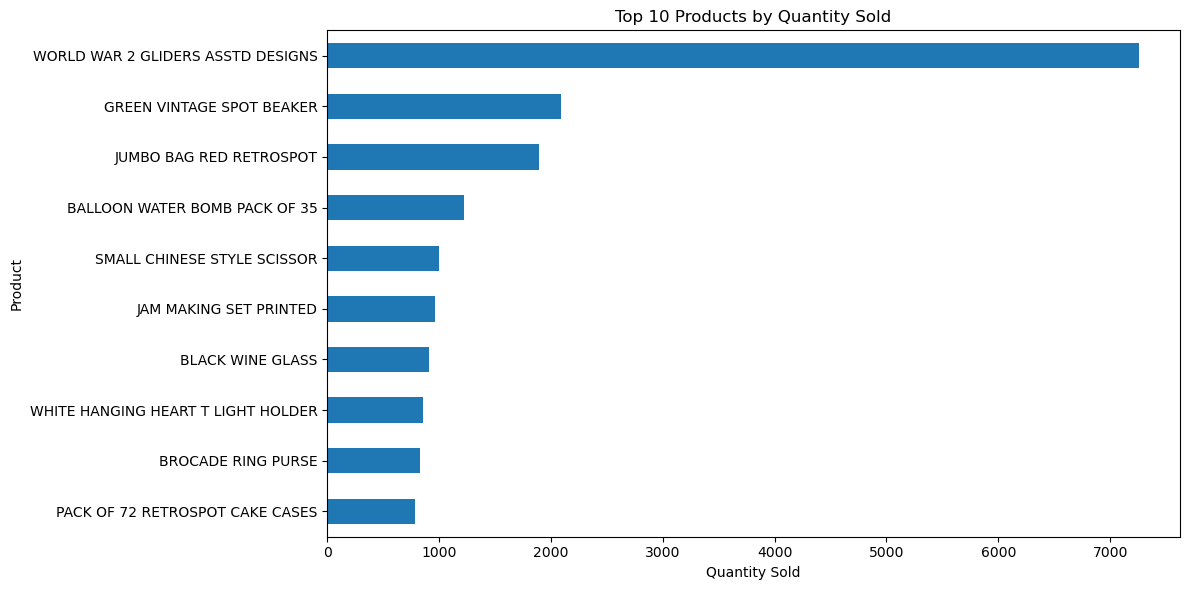

In [19]:
plt.figure(figsize=(12, 6))

top_products_quantity.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [20]:
top_products_revenue = (
    df.groupby("description")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_revenue

description
JUMBO BAG RED RETROSPOT               3495.55
PANTRY ROLLING PIN                    3089.55
REGENCY CAKESTAND 3 TIER              2788.50
POSTAGE                               2641.50
WHITE HANGING HEART T LIGHT HOLDER    2322.85
WOOD BLACK BOARD ANT WHITE FINISH     2298.54
GREEN VINTAGE SPOT BEAKER             2209.44
PARTY BUNTING                         1590.80
WORLD WAR 2 GLIDERS ASSTD DESIGNS     1587.87
VINTAGE UNION JACK MEMOBOARD          1375.25
Name: revenue, dtype: float64

In [21]:
# Exclude postage from physical product analysis
physical_products = df[
    df["description"].str.upper() != "POSTAGE"
]

# Top 10 physical products by revenue
top_physical_products_revenue = (
    physical_products.groupby("description")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_physical_products_revenue

description
JUMBO BAG RED RETROSPOT               3495.55
PANTRY ROLLING PIN                    3089.55
REGENCY CAKESTAND 3 TIER              2788.50
WHITE HANGING HEART T LIGHT HOLDER    2322.85
WOOD BLACK BOARD ANT WHITE FINISH     2298.54
GREEN VINTAGE SPOT BEAKER             2209.44
PARTY BUNTING                         1590.80
WORLD WAR 2 GLIDERS ASSTD DESIGNS     1587.87
VINTAGE UNION JACK MEMOBOARD          1375.25
HOT WATER BOTTLE KEEP CALM            1308.45
Name: revenue, dtype: float64

### Top 10 Products by Revenue

This horizontal bar chart compares the revenue generated by the top 10 physical products.

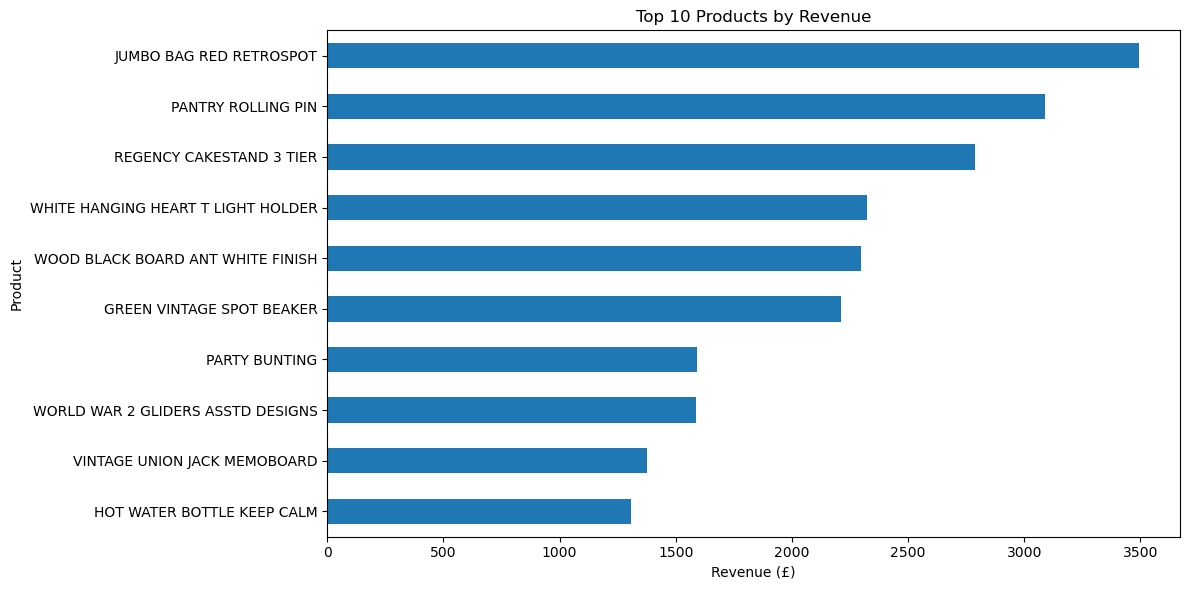

In [22]:
plt.figure(figsize=(12, 6))

top_physical_products_revenue.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

## 6. Monthly Revenue Analysis

This section analyzes revenue by month to identify sales trends and the highest-revenue month.

In [23]:
monthly_revenue = (
    df.groupby("invoice_month")["revenue"]
    .sum()
    .sort_index()
)

monthly_revenue

invoice_month
2010-12-01    14908.49
2011-01-01    11795.80
2011-02-01     8932.32
2011-03-01    12803.82
2011-04-01    10719.97
2011-05-01    17325.19
2011-06-01    13995.70
2011-07-01    16214.30
2011-08-01    16635.89
2011-09-01    28544.06
2011-10-01    26213.20
2011-11-01    31896.91
2011-12-01     6756.16
Name: revenue, dtype: float64

In [24]:
highest_revenue_month = monthly_revenue.idxmax()
highest_month_revenue = monthly_revenue.max()

print("Highest Revenue Month:", highest_revenue_month.strftime("%B %Y"))
print(f"Revenue: £{highest_month_revenue:,.2f}")

Highest Revenue Month: November 2011
Revenue: £31,896.91


### Monthly Revenue Trend

This line chart shows how revenue changes month by month and highlights the highest- and lowest-revenue months.

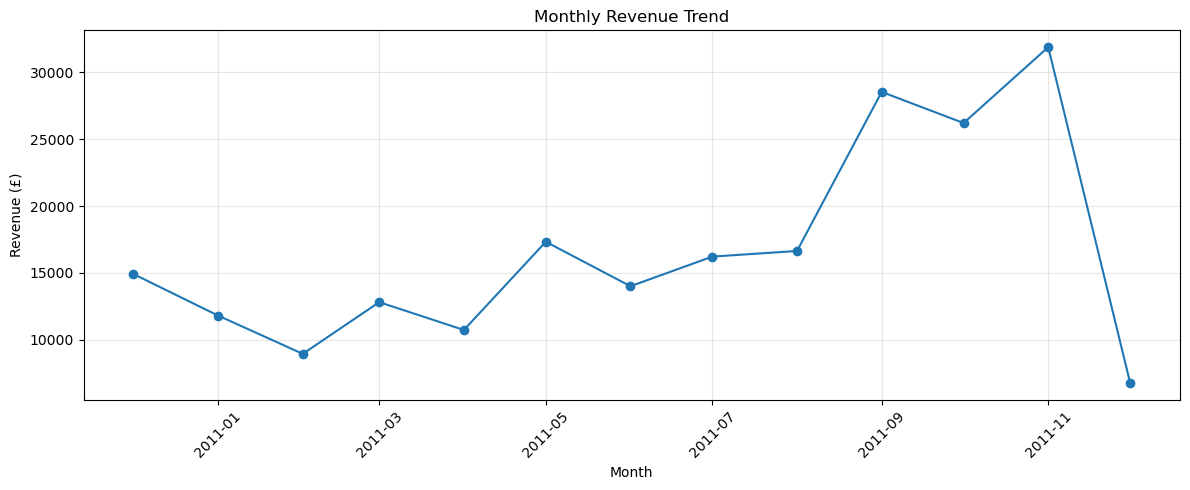

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Country-wise Revenue Analysis

This section compares revenue across countries to identify the largest markets in the dataset.

In [26]:
country_revenue = (
    df.groupby("country")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

country_revenue.head(10)

country
United Kingdom    176602.55
Germany             7251.14
Netherlands         7178.50
EIRE                5966.02
France              4356.87
Australia           1827.02
Switzerland         1695.17
Spain               1674.49
Finland             1493.78
Sweden              1406.06
Name: revenue, dtype: float64

In [27]:
uk_revenue = df.loc[
    df["country"] == "United Kingdom", "revenue"
].sum()

uk_revenue_percentage = (uk_revenue / df["revenue"].sum()) * 100

print(f"UK Revenue: £{uk_revenue:,.2f}")
print(f"UK Share of Total Revenue: {uk_revenue_percentage:.2f}%")

UK Revenue: £176,602.55
UK Share of Total Revenue: 81.48%


### Top 10 Countries by Revenue

This horizontal bar chart compares revenue across the top 10 countries and highlights the UK market's contribution.

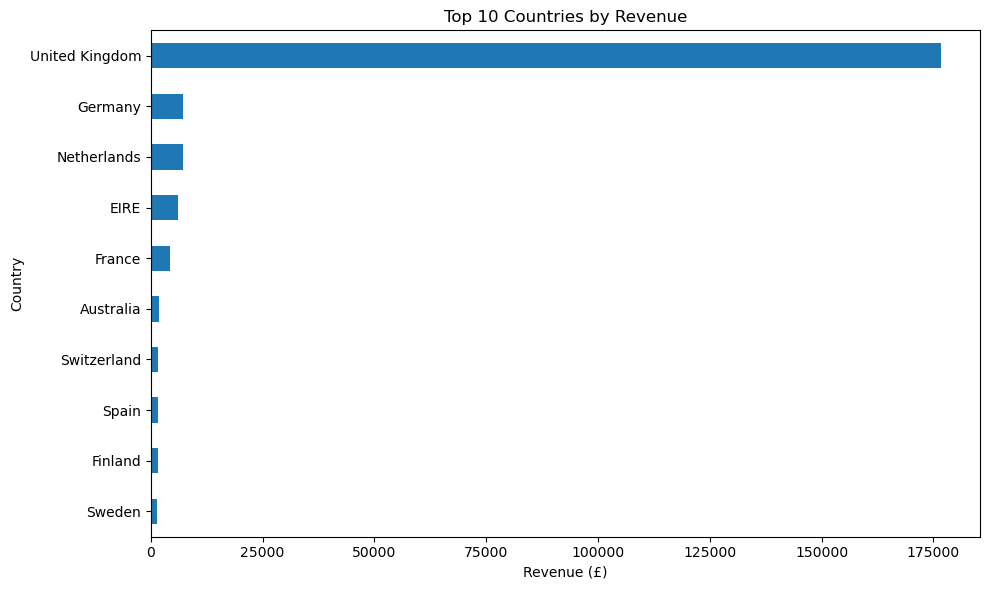

In [28]:
top_countries_revenue = (
    df.groupby("country")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

top_countries_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## 8. Customer Analysis

This section identifies the highest-revenue customers and examines their contribution to sales.

In [29]:
top_customers = (
    df.groupby("customer_id")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

customer_id
17450    8188.46
18102    7564.64
14646    7038.90
14911    3844.58
16684    2784.88
14156    1975.76
16986    1790.00
14298    1670.18
17511    1607.78
13798    1551.46
Name: revenue, dtype: float64

In [30]:
customer_orders = (
    df.groupby("customer_id")
    .agg(
        total_revenue=("revenue", "sum"),
        total_orders=("invoice", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

customer_orders

,total_revenue,total_orders
customer_id,,
17450,8188.46,7
18102,7564.64,8
14646,7038.90,25
14911,3844.58,92
16684,2784.88,7
14156,1975.76,24
16986,1790.00,1
14298,1670.18,16
17511,1607.78,13


## 9. Business Insights and Conclusion

### Key Business Insights

1. **Overall Performance:** The dataset contains 9,999 records after duplicate removal, with total revenue of £216,741.81.
2. **Product Performance:** WORLD WAR 2 GLIDERS ASSTD DESIGNS had the highest quantity sold, with 7,261 items.
3. **Revenue by Product:** JUMBO BAG RED RETROSPOT generated the highest revenue among physical products, at £3,495.55.
4. **Monthly Performance:** November 2011 recorded the highest monthly revenue, at £31,896.91.
5. **Country Performance:** The United Kingdom generated £176,602.55, contributing approximately 81.48% of total revenue.
6. **Customer Performance:** Customer 17450 generated the highest total revenue, at £8,188.46.
7. **Customer Purchase Frequency:** Customer 14911 had 92 unique invoices among the top 10 customers by revenue, highlighting that purchase frequency and total revenue can differ.
8. **Revenue Concentration:** Revenue was heavily concentrated in the UK market, suggesting that further analysis of sales in other countries could help identify opportunities for market diversification.

### Business Recommendations

1. **Expand International Markets:** Investigate opportunities to grow sales in countries outside the UK and reduce dependence on a single market.
2. **Focus on Best-Selling Products:** Review inventory and demand for products generating the highest sales quantities and revenue.
3. **Understand Customer Behavior:** Analyze customer revenue and invoice frequency to identify different purchasing patterns.
4. **Investigate Monthly Trends:** Examine factors behind monthly revenue changes before making sales or inventory decisions.

### Conclusion

This project used Python and Pandas to explore and analyze e-commerce sales data. The analysis covered data cleaning, revenue validation, key performance indicators, product performance, monthly revenue, country-wise revenue, and customer behavior.

The results highlight the leading products, strongest sales month, main country market, and highest-revenue customers in the analyzed dataset.

### Limitations

- The analysis covers a dataset of 10,000 original rows, not necessarily the company's complete sales history.
- Revenue rankings depend on the records and time period available in the dataset.
- Revenue and invoice frequency alone do not explain customer loyalty or profitability.
- Further analysis would be needed to identify the reasons behind sales changes and to make reliable business forecasts.